# Observation windows: one vocabulary for every window the platform uses

This notebook resolves the **observation window vs performance window** confusion and
measures the real window sizes and censoring coverage from the loaded DuckDB.

- Vocabulary and timeline: cells 2-5.
- Measured windows (months on book, censoring, coverage heatmap, `(t0, horizon)` counts): cells 6-11.
- Leakage cross-check against `field_leakage_table` and `feature_catalogue_table`: cells 12-13.

Settings come from `residential_mortgage/_settings/*.toml` via `config.py` and optional
environment overrides `WIN_FULL` (`'0'` = default 0.03% stratified sample, `'1'` = full dataset),
`WIN_DB`, `WIN_OUT`, and `WIN_THREADS`.


In [1]:
%matplotlib inline
import os
import sys
import time
from pathlib import Path

# Set WIN_FULL='1' (or pass $env:WIN_FULL='1' before nbconvert) to run against the full database.
os.environ.setdefault('WIN_FULL', '0')

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

T0 = time.time()

def find_repo_root():
    here = Path.cwd().resolve()
    for folder in [here] + list(here.parents):
        if (folder / 'residential_mortgage').is_dir():
            return folder
    raise RuntimeError('Cannot find the folder that holds residential_mortgage')

REPO = find_repo_root()
PACKAGE_ROOT = REPO / 'residential_mortgage'
if str(PACKAGE_ROOT) not in sys.path:
    sys.path.insert(0, str(PACKAGE_ROOT))

from _settings import config
from _settings import windows as W

USE_FULL = os.environ.get('WIN_FULL', '0') == '1'
USE_SAMPLE = not USE_FULL
DB_PATH = Path(os.environ.get('WIN_DB', config.base_db_path(full=USE_FULL)))
OUT_DIR = Path(os.environ.get('WIN_OUT', config.script_outputs('01_data_foundation', '05_observation_windows', full=USE_FULL)))
CHART_DIR = OUT_DIR / 'charts'
TABLE_DIR = OUT_DIR / 'tables'
CHART_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

_COMPUTE = config.load('compute')
THREADS = int(os.environ['WIN_THREADS']) if os.environ.get('WIN_THREADS') else int(_COMPUTE['duckdb']['threads'])
MEMORY_LIMIT = _COMPUTE['duckdb']['memory_limit']
CHART_DPI = int(_COMPUTE['charts']['dpi'])
_rate_pct = config.load('sampling')['sampling']['rate'] * 100
SCOPE_LABEL = 'full data' if USE_FULL else f'{_rate_pct:.4g}% stratified sample'

con = duckdb.connect(str(DB_PATH), read_only=True)
try:
    con.execute('SET enable_progress_bar = false')
except Exception:
    pass
con.execute(f'SET threads = {THREADS}')
con.execute(f"SET memory_limit = '{MEMORY_LIMIT}'")
SPILL_DIR = REPO / '.scratch' / 'win_tmp'
SPILL_DIR.mkdir(parents=True, exist_ok=True)
con.execute(f"SET temp_directory = '{SPILL_DIR.as_posix()}'")

tables = {r[0] for r in con.execute('SHOW TABLES').fetchall()}
for needed, script in (('field_leakage_table', '03_leakage_audit.py'), ('feature_catalogue_table', '04_feature_catalogue.py')):
    if needed not in tables:
        raise RuntimeError(f'{needed} is missing. Run {script} first.')

print(f'Database: {DB_PATH.name}; scope: {SCOPE_LABEL}; threads: {THREADS}; memory_limit: {MEMORY_LIMIT}')
print(f'Outputs: {OUT_DIR}')
print(f'Windows config: {Path(W.__file__).name}')


Database: mortgages_sample.duckdb; scope: 0.03% stratified sample; threads: 4; memory_limit: 6GB
Outputs: E:\Repos\V4_bank-credit-risk-platform\residential_mortgage\00_data\processed\module_outputs\01_data_foundation\sample\05_observation_windows
Windows config: windows.py


## The vocabulary, once and for all

The two names people confuse: the **observation (feature) window** looks backward from the
snapshot date `t0` and ends at `t0 - 1`; the **performance (outcome) window** looks forward from
`t0` and is where the label is measured. Anything filled inside the performance window that
ends up in a feature is target leakage.

The single source is `residential_mortgage/_settings/windows.py`. The table below is its
`WINDOW_VOCABULARY`.


In [2]:
vocab = pd.DataFrame(W.WINDOW_VOCABULARY)
vocab.to_csv(TABLE_DIR / 'win_vocabulary.csv', index=False)
display(vocab)


,window,direction,definition,value,source
0,Snapshot date (t0),point,The month a model freezes its features and sco...,Every December 2000-2025 (book_snapshot); mont...,"M2-12, M2-13"
1,Observation / feature window,backward,Months before t0 whose values become features....,lookback 6 months (and 12 for worst-12/payment...,feature catalogue; script 9
2,Performance / outcome window,forward,Months after t0 over which the label is measur...,12 months (default); 24 for re-default,M2-9; script 12
3,Sample coverage window,global,"The calendar span of the whole panel, independ...","2000Q1-2025Q4 (104 acquisition quarters), data...",loaded_quarters_table
4,Seasoning window,backward,Minimum months on book before a loan is eligib...,6 months (masked-balance months),M2 data facts
5,Maturity / censoring window,forward,How much of the performance window a loan has ...,measured per vintage in 05_observation_windows...,05_observation_windows.ipynb
6,Cure / probation window,forward,Clean months after default before a loan re-en...,3 months arrears default; 12 months restructuring,"M2-5 (178(5)(a), 178(5A))"
7,Projection horizon,forward,"Forward periods for roll-rate / PD projection,...","[6, 12, 24, 36] months",script 3
8,Emergence lag,forward,Time from first missed payment to recognition ...,3 months behind (90-119 DPD),M2-3 (178(1)(b))


## The timeline

One picture of the vocabulary. The shaded bar left of `t0` is the observation window; the
shaded bar right of `t0` is the performance window. Seasoning sits before the first usable
observation; probation, emergence, and projection all sit after `t0`.


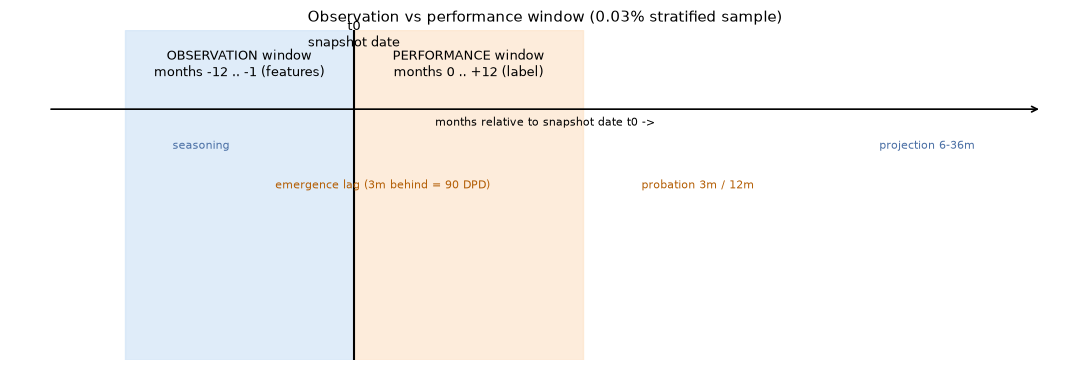

In [3]:
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.set_xlim(-18, 38)
ax.set_ylim(0, 10)
ax.axis('off')

# Observation (feature) window: backward from t0, ends at t0-1
ax.axvspan(-12, 0, color='#cfe3f7', alpha=0.65)
ax.text(-6, 8.6, 'OBSERVATION window\nmonths -12 .. -1 (features)', ha='center', fontsize=9)
# Performance (outcome) window: forward from t0
ax.axvspan(0, 12, color='#fde3c8', alpha=0.65)
ax.text(6, 8.6, 'PERFORMANCE window\nmonths 0 .. +12 (label)', ha='center', fontsize=9)
# t0
ax.axvline(0, color='black', lw=1.5)
ax.text(0, 9.5, 't0\nsnapshot date', ha='center', fontsize=9)
# time axis
ax.annotate('', xy=(36, 7.6), xytext=(-16, 7.6), arrowprops=dict(arrowstyle='->', lw=1.2))
ax.text(10, 7.1, 'months relative to snapshot date t0 ->', ha='center', fontsize=8)
# markers below the axis
ax.annotate('seasoning', xy=(-8, 6.4), ha='center', fontsize=8, color='#4a6fa5')
ax.annotate('emergence lag (3m behind = 90 DPD)', xy=(1.5, 5.2), ha='center', fontsize=8, color='#b45f06')
ax.annotate('probation 3m / 12m', xy=(18, 5.2), ha='center', fontsize=8, color='#b45f06')
ax.annotate('projection 6-36m', xy=(30, 6.4), ha='center', fontsize=8, color='#4a6fa5')
plt.title(f'Observation vs performance window ({SCOPE_LABEL})', fontsize=11)
plt.tight_layout()
fig.savefig(CHART_DIR / 'win_timeline.png', dpi=CHART_DPI)
plt.show()
plt.close(fig)


## Measured windows from the data

Everything below uses 0-based months on book `mob = datediff('month', first_payment_date, reporting_period)`
(not raw `loan_age`, which is NULL on Fannie Mae exit rows). One DuckDB `TEMP TABLE win_per_loan`
aggregates the panel once inside DuckDB so both the `0.03%` sample (`17,275` loans) and the full
`57.6M`-loan dataset run cleanly without pulling millions of rows into Python memory.


In [4]:
t_scan = time.time()
con.execute('''
CREATE OR REPLACE TEMP TABLE win_per_loan AS
WITH edge AS (
    SELECT max(reporting_period) AS max_rp FROM loan_monthly_view
),
m_agg AS (
    SELECT
        l.loan_id,
        l.acquisition_quarter AS vintage,
        l.first_payment_date,
        MIN(datediff('month', l.first_payment_date, m.reporting_period)) AS first_mob,
        MAX(datediff('month', l.first_payment_date, m.reporting_period)) AS last_obs_mob,
        COUNT(*) AS n_months,
        MIN(CASE WHEN m.zero_balance_code IN ('01', '02', '03', '09', '15')
                 THEN datediff('month', l.first_payment_date, m.reporting_period) END) AS realized_exit_mob,
        MIN(CASE WHEN m.zero_balance_code IN ('06', '16', '96')
                 THEN datediff('month', l.first_payment_date, m.reporting_period) END) AS non_credit_exit_mob,
        MIN(CASE WHEN m.zero_balance_code IS NOT NULL
                 THEN datediff('month', l.first_payment_date, m.reporting_period) END) AS any_exit_mob,
        MAX(m.reporting_period) AS last_rp
    FROM loans_table l
    LEFT JOIN loan_monthly_view m ON m.loan_id = l.loan_id
    WHERE l.first_payment_date IS NOT NULL
    GROUP BY l.loan_id, l.acquisition_quarter, l.first_payment_date
)
SELECT
    m_agg.*,
    datediff('month', first_payment_date, edge.max_rp) AS edge_mob,
    edge.max_rp AS data_end
FROM m_agg CROSS JOIN edge
WHERE first_mob IS NOT NULL
''')
n_per_loan, data_end = con.execute('SELECT count(*), min(data_end) FROM win_per_loan').fetchone()
print(f'win_per_loan summary: {n_per_loan:,} loans (data ends {data_end}) in {time.time() - t_scan:.1f}s')

mob_by_vintage = con.execute('''
SELECT
    vintage,
    COUNT(*) AS loans,
    MIN(first_mob) AS min_first_mob,
    MAX(last_obs_mob) AS max_last_mob,
    MEDIAN(last_obs_mob) AS median_last_mob
FROM win_per_loan
GROUP BY vintage
ORDER BY vintage
''').df()
mob_by_vintage.to_csv(TABLE_DIR / 'win_mob_by_vintage.csv', index=False)
display(mob_by_vintage)


win_per_loan summary: 17,275 loans (data ends 2025-12-01) in 0.1s


,vintage,loans,min_first_mob,max_last_mob,median_last_mob
0,2000Q1,74,-1,181,29.5
1,2000Q2,82,-2,120,20.0
2,2000Q3,100,-2,163,17.0
3,2000Q4,109,-2,176,19.0
4,2001Q1,141,-2,215,22.0
...,...,...,...,...,...
99,2024Q4,75,-2,15,12.0
100,2025Q1,58,-2,12,9.0
101,2025Q2,74,-2,8,6.0
102,2025Q3,79,-2,6,3.0


## Censoring: realized exits vs right-censoring at the data edge

At snapshot month `t0` and horizon `h`:
- **Eligible at `t0`:** entered the panel by `t0` (`first_mob <= t0`), observed to at least `t0` (`last_obs_mob >= t0`), and still open entering the window (`any_exit_mob IS NULL OR any_exit_mob > t0`).
- **Complete over `(t0, t0 + h]`:** either observed through `t0 + h` (`last_obs_mob >= t0 + h`), **or** resolved by payoff/credit exit inside `(t0, t0 + h]` (`realized_exit_mob <= t0 + h`, codes `01, 02, 03, 09, 15`). Realized payoffs and defaults inside the window are resolved outcomes, not censored.
- **Right-censored:** incomplete at `data_end` (`2025-12`, `edge_mob < t0 + h`), non-credit removal (`06, 16, 96`), or stopped reporting early without an exit code.


In [5]:
def coverage(t0: int, h: int) -> dict:
    r = con.execute(f'''
    WITH elig AS (
        SELECT *
        FROM win_per_loan
        WHERE first_mob <= {t0}
          AND last_obs_mob >= {t0}
          AND (any_exit_mob IS NULL OR any_exit_mob > {t0})
    ),
    cls AS (
        SELECT
            CASE
                WHEN last_obs_mob >= {t0 + h} AND (non_credit_exit_mob IS NULL OR non_credit_exit_mob > {t0 + h})
                    THEN 'complete_horizon'
                WHEN realized_exit_mob IS NOT NULL AND realized_exit_mob <= {t0 + h}
                    THEN 'complete_exit'
                WHEN non_credit_exit_mob IS NOT NULL AND non_credit_exit_mob <= {t0 + h}
                    THEN 'censored_non_credit'
                WHEN edge_mob < {t0 + h}
                    THEN 'censored_edge'
                ELSE 'censored_gap'
            END AS status
        FROM elig
    )
    SELECT
        COUNT(*) AS eligible,
        COUNT(*) FILTER (WHERE status = 'complete_horizon') AS complete_horizon,
        COUNT(*) FILTER (WHERE status = 'complete_exit') AS complete_exit,
        COUNT(*) FILTER (WHERE status = 'censored_edge') AS censored_edge,
        COUNT(*) FILTER (WHERE status IN ('censored_non_credit', 'censored_gap')) AS censored_other
    FROM cls
    ''').fetchone()
    eligible, comp_h, comp_e, cens_edge, cens_oth = [int(x) for x in r]
    complete_total = comp_h + comp_e
    censored_total = cens_edge + cens_oth
    assert complete_total + censored_total == eligible
    cov_pct = round(100.0 * complete_total / eligible, 2) if eligible else None
    return {
        't0_mob': t0,
        'horizon_months': h,
        'eligible_loans': eligible,
        'complete_reached_horizon': comp_h,
        'complete_realized_exit': comp_e,
        'complete_total': complete_total,
        'censored_data_edge': cens_edge,
        'censored_non_credit_or_gap': cens_oth,
        'censored_total': censored_total,
        'coverage_pct': cov_pct,
    }

rows = [coverage(t0, h) for t0 in [6, 12, 24, 36] for h in [12, 24]]
coverage_df = pd.DataFrame(rows)
coverage_df.to_csv(TABLE_DIR / 'win_coverage_by_t0_horizon.csv', index=False)
display(coverage_df)


,t0_mob,horizon_months,eligible_loans,complete_reached_horizon,complete_realized_exit,complete_total,censored_data_edge,censored_non_credit_or_gap,censored_total,coverage_pct
0,6,12,16323,13707,2336,16043,268,12,280,98.28
1,6,24,16323,11289,4543,15832,477,14,491,96.99
2,12,12,14981,12432,2304,14736,241,4,245,98.36
3,12,24,14981,10316,4177,14493,482,6,488,96.74
4,24,12,12249,10324,1682,12006,241,2,243,98.02
5,24,24,12249,8397,3029,11426,819,4,823,93.28
6,36,12,10192,8398,1214,9612,578,2,580,94.31
7,36,24,10192,6157,2256,8413,1772,7,1779,82.55


## Vintage x months-on-book coverage heatmap

Each cell is the share of a vintage still active/observed at that month on book
(`first_mob <= m AND last_obs_mob >= m`), aggregated inside DuckDB.
Early vintages fade smoothly due to payoffs/defaults; recent vintages stop abruptly at December 2025.


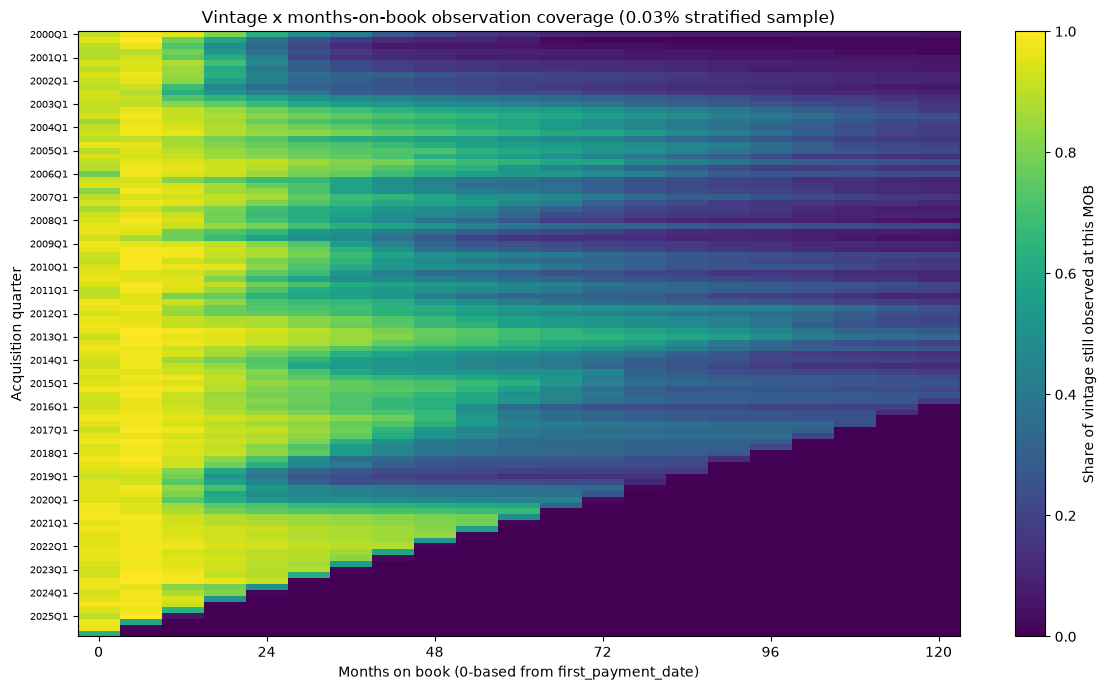

In [6]:
mob_grid = list(range(0, 121, 6))
cols_sql = ', '.join(
    f'CAST(COUNT(*) FILTER (WHERE first_mob <= {m} AND last_obs_mob >= {m}) AS DOUBLE) / COUNT(*) AS mob_{m}'
    for m in mob_grid
)
hm_df = con.execute(f'''
SELECT vintage, {cols_sql}
FROM win_per_loan
GROUP BY vintage
ORDER BY vintage
''').df()
vintages = hm_df['vintage'].tolist()
matrix = hm_df[[f'mob_{m}' for m in mob_grid]].to_numpy(dtype=float)
hm_df.to_csv(TABLE_DIR / 'win_vintage_mob_heatmap.csv', index=False)

fig, ax = plt.subplots(figsize=(12, 7))
im = ax.imshow(matrix, aspect='auto', cmap='viridis', vmin=0, vmax=1)
ax.set_xticks(range(0, len(mob_grid), 4))
ax.set_xticklabels(mob_grid[::4])
ax.set_yticks(range(0, len(vintages), 4))
ax.set_yticklabels(vintages[::4], fontsize=7)
ax.set_xlabel('Months on book (0-based from first_payment_date)')
ax.set_ylabel('Acquisition quarter')
plt.colorbar(im, label='Share of vintage still observed at this MOB')
plt.title(f'Vintage x months-on-book observation coverage ({SCOPE_LABEL})')
plt.tight_layout()
fig.savefig(CHART_DIR / 'win_coverage_heatmap.png', dpi=CHART_DPI)
plt.show()
plt.close(fig)


## Leakage cross-check

Each field is placed in a window from its `field_class` in `field_leakage_table` and
`feature_catalogue_table`. The rule: `quarantined` fields sit inside the performance
window and may only build targets; `monthly_lag_1` fields sit inside the observation
window and are used at `t0 - 1` or earlier.


In [7]:
leakage = con.execute(
    'SELECT field_name, source_object, field_class, lag_rule, usable_as_feature, reason '
    'FROM field_leakage_table ORDER BY field_name').df()
catalogue = con.execute(
    'SELECT field_name, source_object, treatment_note FROM feature_catalogue_table').df()

def window_of(cls):
    return {
        'key': 'outside windows (join/order)',
        'origination': 'before t0 (fixed at origination)',
        'monthly_lag_1': 'observation window, ends t0-1',
        'quarantined': 'performance window (targets only)',
    }[cls]

merged = leakage.merge(catalogue, on=['field_name', 'source_object'], how='left')
merged['window'] = merged['field_class'].map(window_of)
merged.to_csv(TABLE_DIR / 'win_leakage_cross_check.csv', index=False)
display(merged[['field_name', 'source_object', 'field_class', 'lag_rule', 'usable_as_feature', 'window']])
print('Fields inside the performance window (quarantined):',
      int((merged['field_class'] == 'quarantined').sum()))
print('Fields in the observation window (monthly_lag_1):',
      int((merged['field_class'] == 'monthly_lag_1').sum()))
print(f'Total time: {time.time() - T0:.1f}s')
try:
    con.close()
    SPILL_DIR.rmdir()
except OSError:
    pass


,field_name,source_object,field_class,lag_rule,usable_as_feature,window
0,acquisition_quarter,loans_table,key,join only,False,outside windows (join/order)
1,acquisition_quarter,loan_monthly_view,key,join only,False,outside windows (join/order)
2,alt_delinquency_resolution,loan_monthly_view,monthly_lag_1,t-1,True,"observation window, ends t0-1"
3,alt_delinquency_resolution_count,loan_monthly_view,monthly_lag_1,t-1,True,"observation window, ends t0-1"
4,amortization_type,loans_table,origination,none,True,before t0 (fixed at origination)
...,...,...,...,...,...,...
73,total_principal,loan_monthly_view,monthly_lag_1,t-1,True,"observation window, ends t0-1"
74,upb_at_removal,loan_monthly_view,quarantined,never,False,performance window (targets only)
75,zero_balance_code,loan_monthly_view,quarantined,never,False,performance window (targets only)
76,zero_balance_date,loan_monthly_view,quarantined,never,False,performance window (targets only)


Fields inside the performance window (quarantined): 19
Fields in the observation window (monthly_lag_1): 21
Total time: 1.4s


## Where each window constant lives

- Analytical windows and horizons: `residential_mortgage/_settings/windows.py` (this notebook's source).
- Regulatory thresholds (`DPD_DEFAULT_MONTHS`, `PROBATION_ARREARS_MONTHS`, `PROBATION_RESTRUCTURING_MONTHS`, etc.): `residential_mortgage/_settings/regulatory_parameters.py` (re-exported by `windows.py`).
- Downstream consumers: `02_portfolio_analytics/scripts/07_default_rate_history.py` (snapshot/out-of-time gate), `02_portfolio_analytics/scripts/module2_common.py`, and Module 3 scorecard/PD scripts in `03_rating_and_pd/scripts/`.
